# DLENT-RT — Pareto frontier over the objective weights λ (offline)

Kash: *"run a reasonable grid of λ values and give a Pareto frontier"*. Offline analysis only: nothing here enters
the online loop; Phase 0, the reward, s_C and the configs are unchanged.

**Objectives per job** (`dlent_rt.pareto.job_components`, from `dlent_rt.reward`): customer value CV = q·v,
profit PR = φ_job − C_elec, carbon cost CO = s_C·K (minimised, s_C frozen in Phase 0); reward
R(λ) = λ1·CV + λ2·PR − λ3·CO, today λ = (1, 1, 1). The components are computed once and combined linearly for every λ.

**Grid**: λ = 3·w with w on the simplex at step 1/4 (15 points, corners (3,0,0), (0,3,0), (0,0,3) included) plus the
centre (1, 1, 1) (today's reward, not on the 1/4 grid) = 16 points. **7-point subset**: corners, centre, edge
midpoints (1.5, 1.5, 0), (1.5, 0, 1.5), (0, 1.5, 1.5). **Perturbations** (Section 7): the centre and λ_k × 2, × 0.5.

**Models** (instance of notebook 03: committed `configs/default.yaml`, seed 42, no drop filter):
fluid LP OPT (weighted sum) and the standard augmented Chebyshev LP on the fluid problem, G2 job greedy and the
job-level MILP on all 16 points (and the perturbations); StaticPolicy (Phase 0) and DLENT-RT theory on the 7-point
subset and the perturbations, with Phase 0 rebuilt for each λ.

This notebook only READS the cache written by `scripts/pareto_run.py` (`reports/week30/pareto/*.csv`); run that
script first. Build: `python notebooks/src/build.py 04_pareto_lambda --execute`.

In [1]:
import os, subprocess, sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dlent_rt").is_dir())
sys.path.insert(0, str(ROOT))
from dlent_rt import pareto

# named regime (optional): DLENT_REGIME=configs/regime_<name>.yaml -> the cache of scripts/pareto_run.py run with the
# same variable (reports/week30/pareto_<name>/), figures in reports/week30/figs_<name>/
REGIME = os.environ.get("DLENT_REGIME") or None
REGIME_TAG = Path(REGIME).stem.replace("regime_", "") if REGIME else None
PDIR = ROOT / "reports" / "week30" / (f"pareto_{REGIME_TAG}" if REGIME else "pareto")
FIGS = ROOT / "reports" / "week30" / f"figs_{REGIME_TAG}" if REGIME else PDIR / "figs"
FIGS.mkdir(parents=True, exist_ok=True)
for f in ("results.csv", "hypervolume.csv", "perturbations.csv", "lambda_invariance_checks.csv", "meta.csv"):
    if not (PDIR / f).is_file():
        raise FileNotFoundError(f"{PDIR / f} missing: run `dlent_venv/bin/python scripts/pareto_run.py` first")
ALL = pd.read_csv(PDIR / "results.csv")
HV = pd.read_csv(PDIR / "hypervolume.csv")
PERT = pd.read_csv(PDIR / "perturbations.csv")
CHK = pd.read_csv(PDIR / "lambda_invariance_checks.csv")
META = pd.read_csv(PDIR / "meta.csv", index_col=0)["value"]
_git = lambda *a: subprocess.check_output(["git", "-C", str(ROOT), *a], text=True).strip()
NB_COMMIT = _git("rev-parse", "HEAD")
NB_BLOB = _git("rev-parse", "HEAD:configs/default.yaml")
print(f"NB04 RUN MARKER  notebook built at commit {NB_COMMIT}; results cached at commit {META['commit']}")
print(f"configs/default.yaml blob: results {META['configs/default.yaml blob']}, notebook HEAD {NB_BLOB}"
      f" ({'same' if META['configs/default.yaml blob'] == NB_BLOB else 'DIFFERENT'})")
print(f"config file used: {META['config']}")
if REGIME:
    NB_REGIME_BLOB = _git("rev-parse", f"HEAD:{REGIME}")
    assert META.get("regime") == REGIME, (META.get("regime"), REGIME)
    print(f"regime {REGIME}: blob results {META['regime blob']}, notebook HEAD {NB_REGIME_BLOB} "
          f"({'same' if META['regime blob'] == NB_REGIME_BLOB else 'DIFFERENT'}); capacity (norm) {META['capacity (norm) cpu, ram']}")
    # the job components (CV, PR, CO) and s_C do not depend on the capacity without the drop filter: s_C = 228.18
    assert abs(float(META["s_C"]) - 228.18428294842903) < 1e-9, META["s_C"]
    print("s_C unchanged by the regime:", META["s_C"])
print(f"seed {META['seed']}  |stream| = {int(float(META['n_stream'])):,}  T = {int(float(META['T'])):,}  "
      f"s_C = {float(META['s_C']):.4f} $/kgCO2  Chebyshev rho = {META['chebyshev rho']}")
ALL["lambda"] = [f"({a:g}, {b:g}, {c:g})" for a, b, c in zip(ALL.l1, ALL.l2, ALL.l3)]
RES = ALL[ALL.on_grid | ALL.in_subset7].copy()          # the grid and the 7-point subset (perturbations: Section 7)
MODELS = ["job-level MILP", "fluid LP OPT", "Chebyshev fluid LP", "G2 job greedy", "StaticPolicy (Phase 0)",
          "DLENT-RT theory"]
STYLE = {"job-level MILP": ("black", "o"), "fluid LP OPT": ("dimgray", "s"), "Chebyshev fluid LP": ("teal", "^"),
         "G2 job greedy": ("steelblue", "D"), "StaticPolicy (Phase 0)": ("darkorange", "v"),
         "DLENT-RT theory": ("crimson", "P")}


def savefig(fig, name):
    fig.savefig(FIGS / f"{name}.png", dpi=200, bbox_inches="tight")


def at(df, model, lam):
    r = df[(df.model == model) & np.isclose(df.l1, lam[0]) & np.isclose(df.l2, lam[1]) & np.isclose(df.l3, lam[2])]
    return r.iloc[0] if len(r) else None

NB04 RUN MARKER  notebook built at commit 3549fc97caa8d93b2d86262bc166391a07aad322; results cached at commit 3549fc97caa8d93b2d86262bc166391a07aad322
configs/default.yaml blob: results 68e7bd76b57c376cae6d74139f11cc456559520b, notebook HEAD 68e7bd76b57c376cae6d74139f11cc456559520b (same)
config file used: git show HEAD:configs/default.yaml + capacity of git show HEAD:configs/regime_small_cluster.yaml -> temporary file (deleted after loading); the working-copy configs/default.yaml is not read
regime configs/regime_small_cluster.yaml: blob results a0d29b5313ea41184961aa085366bc988c5dd7d0, notebook HEAD a0d29b5313ea41184961aa085366bc988c5dd7d0 (same); capacity (norm) [0.4014237441083392, 0.2616208305922613]
s_C unchanged by the regime: 228.18428294842903
seed 42  |stream| = 15,308  T = 1,432,910  s_C = 228.1843 $/kgCO2  Chebyshev rho = 0.001


## 1. λ-invariance of Phase 0 (checked before the subset runs)

Phase 0 is rebuilt with each λ of the subset and of the perturbations through `run_phase0`. s_C (quantile_linear on
λ-free CV and |PR|), the valuation grid, the hardware profiles and the per-job components must not change with λ;
only r̃, τ and λ* do.

In [2]:
display(CHK)
assert CHK[["s_C same as (1,1,1)", "grid edges same", "hardware profiles same", "job components same"]].all().all()

,l1,l2,l3,s_C,"s_C same as (1,1,1)",grid edges same,hardware profiles same,job components same,tau_0,DLENT end reasons,DLENT runtime s
0,3.0,0.0,0.0,228.184283,True,True,True,True,[0.049146 0.077135],"{'test1': 2, 'test2': 0, 'test3': 0, 'timeout'...",449.297144
1,0.0,3.0,0.0,228.184283,True,True,True,True,[0.018266 0.024516],"{'test1': 1, 'test2': 0, 'test3': 0, 'timeout'...",416.757895
2,0.0,0.0,3.0,228.184283,True,True,True,True,[0. 0.],"{'test1': 0, 'test2': 0, 'test3': 0, 'timeout'...",126.171743
3,1.0,1.0,1.0,228.184283,True,True,True,True,[0. 0.020386],"{'test1': 1, 'test2': 1, 'test3': 0, 'timeout'...",370.951268
4,1.5,1.5,0.0,228.184283,True,True,True,True,[0.034636 0.044358],"{'test1': 2, 'test2': 1, 'test3': 0, 'timeout'...",380.544087
5,1.5,0.0,1.5,228.184283,True,True,True,True,[0. 0.010304],"{'test1': 2, 'test2': 0, 'test3': 0, 'timeout'...",254.334686
6,0.0,1.5,1.5,228.184283,True,True,True,True,[0. 0.],"{'test1': 2, 'test2': 1, 'test3': 0, 'timeout'...",215.304762
7,2.0,1.0,1.0,228.184283,True,True,True,True,[0.00746 0.059903],"{'test1': 2, 'test2': 1, 'test3': 0, 'timeout'...",299.177546
8,0.5,1.0,1.0,228.184283,True,True,True,True,[0. 0.],"{'test1': 3, 'test2': 1, 'test3': 0, 'timeout'...",213.279908
9,1.0,2.0,1.0,228.184283,True,True,True,True,[0. 0.033903],"{'test1': 1, 'test2': 1, 'test3': 0, 'timeout'...",283.198645


## 2. Results: one row per (model, λ)

Σ CV, Σ PR, Σ CO in $ over the stream (fluid rows: per tick × T; "n admitted" for the fluid rows is the expected number
of admissions Σ p x · T). "scalarised" = λ1·ΣCV + λ2·ΣPR − λ3·ΣCO; for the Chebyshev rows `chebyshev_t` is the
epigraph value and `dominance_slack` the LP test of Pareto optimality (0 = not dominated). `nondominated` =
non-dominated among the same model's points (CV, PR maximised, CO minimised).

In [3]:
cols = ["model", "lambda", "sum_CV", "sum_PR", "sum_CO", "scalarised", "n_admitted", "nondominated", "runtime_s"]
for m in MODELS:
    g = RES[RES.model == m][cols + [c for c in ("status", "gap", "chebyshev_t", "dominance_slack", "phys_rejects")
                                     if c in RES]]
    print(f"\n=== {m} ({len(g)} points)")
    display(g.drop(columns="model").set_index("lambda").style.format(precision=2))


=== job-level MILP (16 points)


,sum_CV,sum_PR,sum_CO,scalarised,n_admitted,nondominated,runtime_s,status,gap,chebyshev_t,dominance_slack,phys_rejects
lambda,,,,,,,,,,,,
"(0, 0, 3)",0.00,0.00,0.00,0.00,0.00,True,0.00,no job with R > 0,0.00,nan,nan,nan
"(0, 0.75, 2.25)",67975.97,29207.74,3051.30,15040.38,7970.00,True,0.26,Optimization terminated successfully. (HiGHS Status 7: Optimal),0.00,nan,nan,nan
"(0, 1.5, 1.5)",84617.02,34465.80,5873.76,42888.05,9329.00,True,2.16,Optimization terminated successfully. (HiGHS Status 7: Optimal),0.00,nan,nan,nan
"(0, 2.25, 0.75)",86445.11,35101.44,6852.02,73839.22,9626.00,True,5.87,Optimization terminated successfully. (HiGHS Status 7: Optimal),0.00,nan,nan,nan
"(0, 3, 0)",87068.76,35183.73,7283.28,105551.19,9702.00,True,11.54,Optimization terminated successfully. (HiGHS Status 7: Optimal),0.00,nan,nan,nan
"(0.75, 0, 2.25)",94299.66,20445.02,5814.82,57641.41,10797.00,True,4.97,Optimization terminated successfully. (HiGHS Status 7: Optimal),0.00,nan,nan,nan
"(0.75, 0.75, 1.5)",93947.71,33168.26,6659.13,85348.29,10612.00,True,12.78,Optimization terminated successfully. (HiGHS Status 7: Optimal),0.00,nan,nan,nan
"(0.75, 1.5, 0.75)",93437.33,34157.96,7172.14,115935.83,10464.00,True,9.13,Optimization terminated successfully. (HiGHS Status 7: Optimal),0.00,nan,nan,nan
"(0.75, 2.25, 0)",92833.59,34487.61,7442.89,147222.32,10348.00,True,11.29,Optimization terminated successfully. (HiGHS Status 7: Optimal),0.00,nan,nan,nan



=== fluid LP OPT (16 points)


,sum_CV,sum_PR,sum_CO,scalarised,n_admitted,nondominated,runtime_s,status,gap,chebyshev_t,dominance_slack,phys_rejects
lambda,,,,,,,,,,,,
"(0, 0, 3)",0.00,0.00,0.00,0.00,0.00,True,0.01,Optimal,nan,nan,0.00,nan
"(0, 0.75, 2.25)",62204.45,24855.31,2795.64,12351.30,6588.00,True,0.01,Optimal,nan,nan,0.00,nan
"(0, 1.5, 1.5)",95783.48,35227.67,8933.26,39441.61,8739.00,True,0.01,Optimal,nan,nan,0.00,nan
"(0, 2.25, 0.75)",109761.76,39876.43,16318.22,77483.30,9830.49,True,0.02,Optimal,nan,nan,0.00,nan
"(0, 3, 0)",110476.86,40079.63,17359.18,120238.90,9913.83,True,0.03,Optimal,nan,nan,-0.00,nan
"(0.75, 0, 2.25)",114679.99,22993.37,9693.23,64200.21,11572.00,True,0.01,Optimal,nan,nan,0.00,nan
"(0.75, 0.75, 1.5)",124918.97,35462.26,15425.61,97147.51,11765.00,True,0.02,Optimal,nan,nan,0.00,nan
"(0.75, 1.5, 0.75)",125280.75,37909.16,17416.03,137762.28,11451.22,True,0.03,Optimal,nan,nan,0.00,nan
"(0.75, 2.25, 0)",123962.68,38527.86,17633.40,179659.69,11158.26,True,0.03,Optimal,nan,nan,-0.00,nan



=== Chebyshev fluid LP (16 points)


...

,sum_CV,sum_PR,sum_CO,scalarised,n_admitted,nondominated,runtime_s,status,gap,chebyshev_t,dominance_slack,phys_rejects
lambda,,,,,,,,,,,,
"(0, 0, 3)",0.00,0.00,0.00,0.00,0.00,True,0.24,nan,nan,nan,nan,0.00
"(0, 0.75, 2.25)",67723.56,29077.37,3047.29,14951.63,7959.00,True,0.17,nan,nan,nan,nan,76.00
"(0, 1.5, 1.5)",80534.35,33050.14,5766.53,40925.40,9317.00,True,0.22,nan,nan,nan,nan,789.00
"(0, 2.25, 0.75)",80334.32,33056.36,7060.04,69081.78,9529.00,True,0.18,nan,nan,nan,nan,1901.00
"(0, 3, 0)",79713.60,32665.47,7320.29,97996.42,9600.00,False,0.18,nan,nan,nan,nan,3092.00
"(0.75, 0, 2.25)",89009.11,18733.87,5646.66,54051.85,10847.00,True,0.24,nan,nan,nan,nan,856.00
"(0.75, 0.75, 1.5)",85394.69,31213.00,6790.67,77269.77,10497.00,True,0.18,nan,nan,nan,nan,1513.00
"(0.75, 1.5, 0.75)",83017.46,31752.80,7469.33,104290.29,10293.00,True,0.18,nan,nan,nan,nan,2443.00
"(0.75, 2.25, 0)",82597.80,31799.41,7564.90,133497.02,10187.00,True,0.22,nan,nan,nan,nan,3432.00



=== StaticPolicy (Phase 0) (7 points)


,sum_CV,sum_PR,sum_CO,scalarised,n_admitted,nondominated,runtime_s,status,gap,chebyshev_t,dominance_slack,phys_rejects
lambda,,,,,,,,,,,,
"(3, 0, 0)",42331.40,8113.51,4594.07,126994.19,9887.00,False,0.28,nan,nan,nan,nan,675.00
"(0, 3, 0)",38090.47,8951.00,4700.36,26853.01,8419.00,True,0.22,nan,nan,nan,nan,676.00
"(0, 0, 3)",0.00,0.00,0.00,0.00,0.00,True,0.16,nan,nan,nan,nan,0.00
"(1, 1, 1)",40572.86,8814.15,4670.07,44716.94,9237.00,True,0.25,nan,nan,nan,nan,670.00
"(1.5, 1.5, 0)",40574.29,8820.86,4676.22,74092.73,9231.00,True,0.20,nan,nan,nan,nan,676.00
"(1.5, 0, 1.5)",42382.34,8192.68,4578.23,56706.16,9847.00,True,0.20,nan,nan,nan,nan,722.00
"(0, 1.5, 1.5)",37207.47,8276.12,3516.14,7139.97,8026.00,True,0.18,nan,nan,nan,nan,269.00



=== DLENT-RT theory (7 points)


,sum_CV,sum_PR,sum_CO,scalarised,n_admitted,nondominated,runtime_s,status,gap,chebyshev_t,dominance_slack,phys_rejects
lambda,,,,,,,,,,,,
"(3, 0, 0)",38903.12,7116.97,4407.33,116709.36,7423.00,True,449.30,nan,nan,nan,nan,791.00
"(0, 3, 0)",32541.34,5790.92,3911.79,17372.76,5944.00,True,416.76,nan,nan,nan,nan,559.00
"(0, 0, 3)",0.00,0.00,0.00,0.00,0.00,True,126.17,nan,nan,nan,nan,0.00
"(1, 1, 1)",37633.19,7317.65,4058.71,40892.14,6657.00,True,370.95,nan,nan,nan,nan,537.00
"(1.5, 1.5, 0)",37784.23,7291.63,4235.09,67613.79,6738.00,True,380.54,nan,nan,nan,nan,766.00
"(1.5, 0, 1.5)",40327.00,5938.84,3977.71,54523.94,7265.00,True,254.33,nan,nan,nan,nan,509.00
"(0, 1.5, 1.5)",34337.94,5734.72,3032.21,4053.76,5576.00,True,215.30,nan,nan,nan,nan,169.00


## 3. Corners and degenerate cases

* λ = (3, 0, 0): R = 3·CV = 3·q·v > 0 for every job. The job-level models (MILP, G2) want every job and are limited
  by the per-tick capacity only; the fluid LP admits every type if its average capacity is slack (the default
  cluster), otherwise a fraction; StaticPolicy and DLENT-RT admit every type seen in H (types unseen in H have r̃ = 0)
  up to the physical gate (and thinning).
* λ = (0, 3, 0): R = 3·PR, admit the jobs with φ_job > C_elec (the profitable ones), carbon ignored.
* λ = (0, 0, 3): R = −3·CO ≤ 0 for every job: **admit nothing** for every weighted-sum model (a job with K = 0 has
  R = 0, not > 0). The frontier point is (0, 0, 0): degenerate.
* Chebyshev corners (standard form): w_k = 0 objectives carry no constraint but stay in the augmentation term, so the
  corner w = e_k maximises objective k and breaks ties towards the other two (CO corner: admit nothing).

In [4]:
corner = RES[[any(np.allclose((a, b, c), k) for k in pareto.CORNERS) for a, b, c in zip(RES.l1, RES.l2, RES.l3)]]
corner = corner[corner.model.isin(MODELS)]
def label(r):
    if r.n_admitted == 0:
        return "admit nothing (degenerate: R <= 0 for every job)"
    if r.l1 > 0:                                           # CV corner: R = 3 q v > 0 for every job
        if r.model in ("fluid LP OPT", "Chebyshev fluid LP"):
            if r.n_admitted >= float(META["n_stream"]) - 0.5:
                return "every type admitted (x = 1): the average-occupancy capacity is slack"
            return "capacity binds on average: the fluid LP admits a fraction of the types"
        if r.model in ("StaticPolicy (Phase 0)", "DLENT-RT theory"):
            return ("every type SEEN in H has r~ > 0 (unseen types have r~ = 0 and stay rejected); "
                    "then the physical gate" + (" and thinning" if r.model.startswith("DLENT") else ""))
        return "every job has R > 0: admit-all up to the per-tick capacity"
    if r.l3 > 0:                                           # CO corner: only Chebyshev admits anything
        return "admit only (near-)zero-carbon types: the augmentation term breaks the tie at CO = 0"
    return "admit the profitable jobs / types (PR > 0), carbon ignored"
corner = corner.assign(corner_solution=corner.apply(label, axis=1))
display(corner[["model", "lambda", "n_admitted", "sum_CV", "sum_PR", "sum_CO", "corner_solution"]]
        .set_index(["lambda", "model"]).sort_index().style.format(precision=2))

## 4. Frontier projections

Two-dimensional projections of the three-objective points (CO on the x axis, minimised). Filled markers =
non-dominated within the model; the centre λ = (1, 1, 1) is circled.

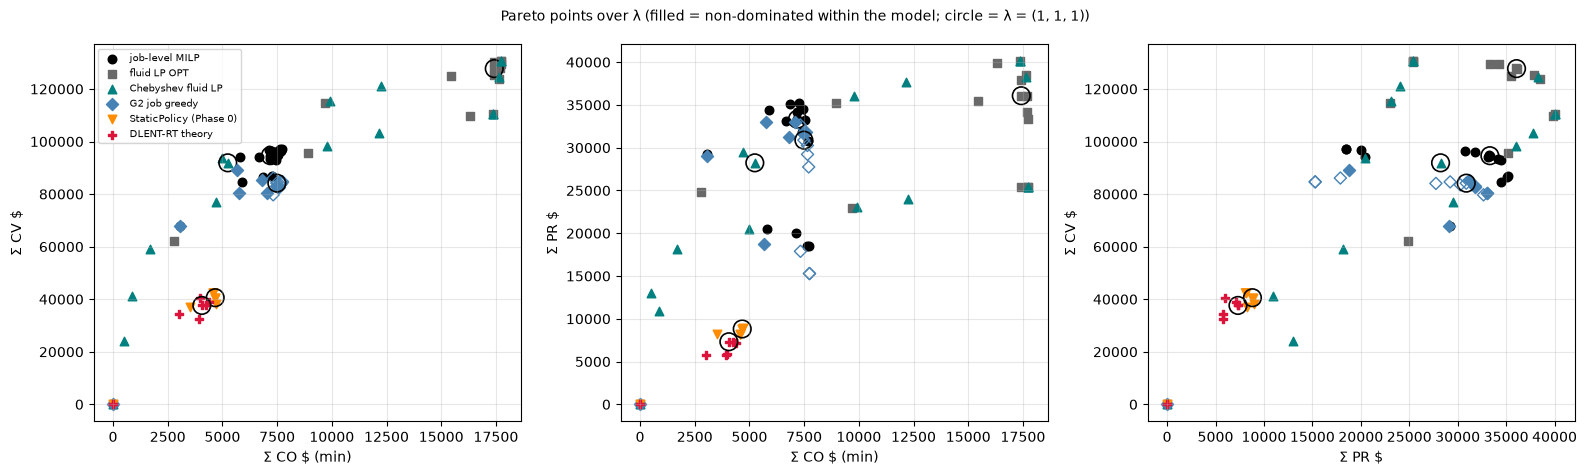

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
pairs = [("sum_CO", "sum_CV", "Σ CO $ (min)", "Σ CV $"), ("sum_CO", "sum_PR", "Σ CO $ (min)", "Σ PR $"),
         ("sum_PR", "sum_CV", "Σ PR $", "Σ CV $")]
for ax, (xc, yc, xl, yl) in zip(axes, pairs):
    for m in MODELS:
        g = RES[RES.model == m]
        col, mk = STYLE[m]
        nd = g.nondominated.astype(bool)
        ax.scatter(g.loc[nd, xc], g.loc[nd, yc], color=col, marker=mk, s=38, label=m)
        ax.scatter(g.loc[~nd, xc], g.loc[~nd, yc], facecolors="none", edgecolors=col, marker=mk, s=38)
        cen = g[(g.l1 == 1) & (g.l2 == 1) & (g.l3 == 1)]
        ax.scatter(cen[xc], cen[yc], facecolors="none", edgecolors="k", s=160, lw=1.2)
    ax.set_xlabel(xl); ax.set_ylabel(yl); ax.grid(alpha=0.3)
axes[0].legend(fontsize=7)
fig.suptitle("Pareto points over λ (filled = non-dominated within the model; circle = λ = (1, 1, 1))", fontsize=10)
plt.tight_layout(); savefig(fig, "pareto_projections"); plt.show()

## 5. Simplex heat maps (job-level MILP and fluid LP)

Each point of the weight simplex w = λ/3 is drawn at barycentric coordinates (vertices: CV = w (1,0,0) bottom left,
PR = (0,1,0) bottom right, CO = (0,0,1) top); colour = linear interpolation over the 16 grid points (Delaunay
triangulation), dots = the grid points with their value in k$. Columns: scalarised reward Σ R(λ), Σ CV, Σ PR, Σ CO.

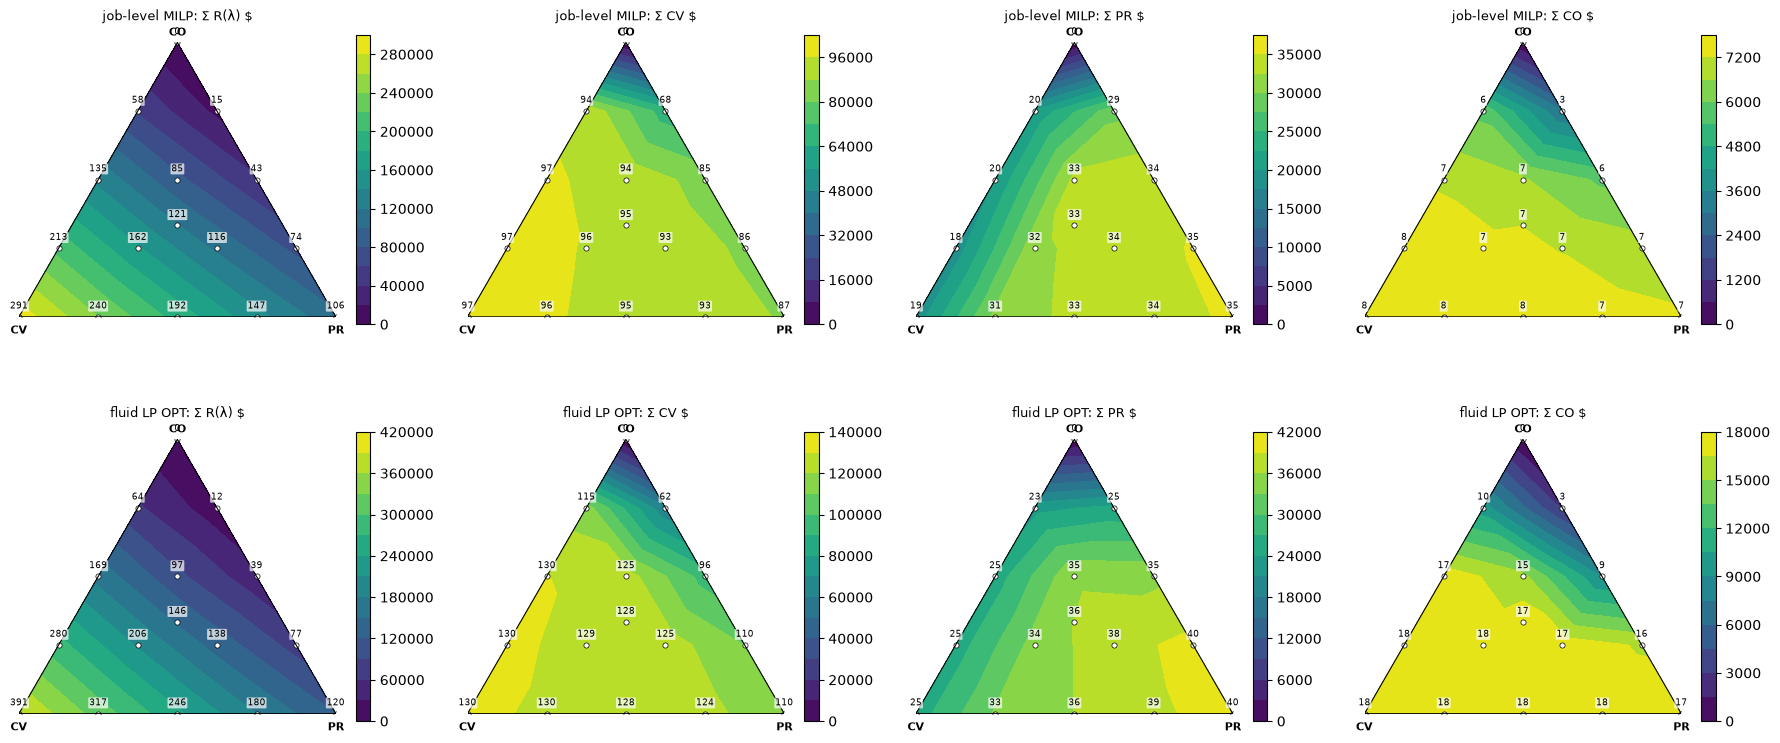

In [6]:
def bary(l1, l2, l3):
    w = np.column_stack([l1, l2, l3]) / 3.0
    return w[:, 1] + w[:, 2] / 2, w[:, 2] * np.sqrt(3) / 2

QTY = [("scalarised", "Σ R(λ) $"), ("sum_CV", "Σ CV $"), ("sum_PR", "Σ PR $"), ("sum_CO", "Σ CO $")]
fig, axes = plt.subplots(2, 4, figsize=(18, 8.4))
for row_ax, m in zip(axes, ["job-level MILP", "fluid LP OPT"]):
    g = RES[(RES.model == m) & RES.on_grid]
    x, y = bary(g.l1.to_numpy(), g.l2.to_numpy(), g.l3.to_numpy())
    tri = mtri.Triangulation(x, y)
    for ax, (qc, ql) in zip(row_ax, QTY):
        z = g[qc].to_numpy()
        cs = ax.tricontourf(tri, z, levels=14, cmap="viridis")
        ax.scatter(x, y, c="w", s=14, edgecolors="k", lw=0.5)
        for xi, yi, zi in zip(x, y, z):
            ax.annotate(f"{zi / 1e3:.0f}", (xi, yi), textcoords="offset points", xytext=(0, 6), ha="center",
                        fontsize=6.5, color="k", bbox=dict(boxstyle="round,pad=0.1", fc="w", ec="none", alpha=0.7))
        ax.plot([0, 1, 0.5, 0], [0, 0, np.sqrt(3) / 2, 0], "k-", lw=0.8)
        for (vx, vy, t) in ((0, 0, "CV"), (1, 0, "PR"), (0.5, np.sqrt(3) / 2, "CO")):
            ax.annotate(t, (vx, vy), textcoords="offset points", xytext=(0, -12 if vy == 0 else 5), ha="center",
                        fontsize=8, weight="bold")
        ax.set_aspect("equal"); ax.axis("off")
        ax.set_title(f"{m}: {ql}", fontsize=9, pad=16)
        fig.colorbar(cs, ax=ax, shrink=0.7)
plt.tight_layout(); savefig(fig, "simplex_heatmaps"); plt.show()

## 6. DLENT-RT and StaticPolicy (Phase 0) vs the offline frontier (7-point subset)

* **% of fluid / % of job MILP**: the policy's scalarised reward Σ R(λ) divided by the fluid OPT's and by the job
  MILP's scalarised reward at the same λ (undefined at λ = (0, 0, 3), where both are 0).
* **Distance to the offline Pareto set.** Offline set P = the non-dominated points of the union of the job-level
  MILP, fluid LP OPT, Chebyshev fluid LP and G2 points on the 16-point grid. Objectives (CV, PR, −CO) maximised and
  normalised by their range over P. Two distances of a point p to P:
  * d₂ = min_{o ∈ P} ‖(o − p) / range‖₂ (normalised Euclidean distance to the nearest offline Pareto point);
  * ε = min_{o ∈ P} max_k (o_k − p_k) / range_k (additive ε-indicator: the smallest uniform improvement, as a share of
    each objective's range, after which p would weakly dominate some o; ε ≤ 0 means p already does).

In [7]:
OFF = RES[RES.on_grid & RES.model.isin(["job-level MILP", "fluid LP OPT", "Chebyshev fluid LP", "G2 job greedy"])]
FO = np.column_stack([OFF.sum_CV, OFF.sum_PR, -OFF.sum_CO])
P = FO[pareto.nondominated(FO)]
rng = np.where(P.max(axis=0) - P.min(axis=0) > 0, P.max(axis=0) - P.min(axis=0), 1.0)
rows = []
for m in ["StaticPolicy (Phase 0)", "DLENT-RT theory"]:
    for lam in pareto.subset7():
        r, fl, jm = at(RES, m, lam), at(RES, "fluid LP OPT", lam), at(RES, "job-level MILP", lam)
        p = np.array([r.sum_CV, r.sum_PR, -r.sum_CO])
        diff = (P - p) / rng
        rows.append({"model": m, "lambda": r["lambda"], "scalarised $": r.scalarised,
                     "% of fluid OPT": 100 * r.scalarised / fl.scalarised if fl.scalarised else np.nan,
                     "% of job MILP": 100 * r.scalarised / jm.scalarised if jm.scalarised else np.nan,
                     "d2 to offline Pareto set": float(np.sqrt((diff ** 2).sum(axis=1)).min()),
                     "eps to offline Pareto set": float(diff.max(axis=1).min())})
VSF = pd.DataFrame(rows).set_index(["model", "lambda"])
print(f"offline Pareto set: {len(P)} non-dominated points out of {len(FO)}; normalisation ranges (CV, PR, -CO) $ = "
      f"{np.round(rng, 2).tolist()}")
display(VSF.style.format(precision=3))

offline Pareto set: 51 non-dominated points out of 64; normalisation ranges (CV, PR, -CO) $ = [130453.8, 40079.63, 17745.36]


## 7. Does every λ matter? (Kash) — perturbations around the centre

For each λ_k scaled × 2 and × 0.5 (the other two at 1), relative to the centre solution λ = (1, 1, 1) of the same
model: jobs added / dropped (fluid LP: EXPECTED jobs, T·Σ_j p_j·(x_j − x0_j)⁺ and (x0_j − x_j)⁺) and the change
in each component. "jobs changed" = added + dropped. DLENT-RT was run on the 6 perturbations (runtime below).

DLENT-RT perturbation runs: sum of run times 1,502 s; all StaticPolicy / DLENT-RT runs in parallel: wall 1,025 s

=== fluid LP OPT


,n_admitted centre,n_admitted,jobs added,jobs dropped,jobs changed,d sum_CV,d sum_PR,d sum_CO
perturbation,,,,,,,,
lambda1 x2,11905.3,12403.1,541.5,43.7,585.2,1597.0,-1856.3,259.7
lambda1 x0.5,11905.3,11423.5,101.7,583.5,685.2,-3202.6,1685.2,-715.4
lambda2 x2,11905.3,11451.2,50.2,504.3,554.5,-2461.9,1832.6,-7.9
lambda2 x0.5,11905.3,12345.7,526.7,86.3,613.0,1334.5,-1829.4,-33.8
lambda3 x2,11905.3,11765.0,102.0,242.3,344.3,-2823.6,-614.2,-1998.3
lambda3 x0.5,11905.3,11940.2,67.7,32.8,100.5,163.2,26.8,228.0



=== G2 job greedy


,n_admitted centre,n_admitted,jobs added,jobs dropped,jobs changed,d sum_CV,d sum_PR,d sum_CO
perturbation,,,,,,,,
lambda1 x2,10616.0,10901.0,469.0,184.0,653.0,489.2,-1663.0,166.1
lambda1 x0.5,10616.0,10228.0,154.0,542.0,696.0,-290.8,1137.7,-378.7
lambda2 x2,10616.0,10293.0,89.0,412.0,501.0,-1137.8,867.9,-19.3
lambda2 x0.5,10616.0,10885.0,357.0,88.0,445.0,714.7,-1174.9,-67.3
lambda3 x2,10616.0,10497.0,237.0,356.0,593.0,1239.4,328.2,-698.0
lambda3 x0.5,10616.0,10632.0,130.0,114.0,244.0,-371.6,-413.2,144.0



=== job-level MILP


...


=== StaticPolicy (Phase 0)


,n_admitted centre,n_admitted,jobs added,jobs dropped,jobs changed,d sum_CV,d sum_PR,d sum_CO
perturbation,,,,,,,,
lambda1 x2,9237.0,9469.0,310.0,78.0,388.0,686.4,-553.8,-184.6
lambda1 x0.5,9237.0,8959.0,23.0,301.0,324.0,-478.5,285.9,-16.3
lambda2 x2,9237.0,9018.0,57.0,276.0,333.0,-546.9,341.2,73.4
lambda2 x0.5,9237.0,9473.0,287.0,51.0,338.0,654.2,-559.9,-70.8
lambda3 x2,9237.0,9164.0,106.0,179.0,285.0,-30.5,-36.3,-560.3
lambda3 x0.5,9237.0,9226.0,23.0,34.0,57.0,-5.2,-3.4,15.0



=== DLENT-RT theory


,n_admitted centre,n_admitted,jobs added,jobs dropped,jobs changed,d sum_CV,d sum_PR,d sum_CO
perturbation,,,,,,,,
lambda1 x2,6657.0,6957.0,398.0,98.0,496.0,789.9,-1080.0,205.3
lambda1 x0.5,6657.0,6432.0,574.0,799.0,1373.0,831.7,-1562.1,-312.3
lambda2 x2,6657.0,6442.0,21.0,236.0,257.0,-736.8,-24.5,15.1
lambda2 x0.5,6657.0,6873.0,704.0,488.0,1192.0,2087.7,-1613.8,-84.4
lambda3 x2,6657.0,6574.0,601.0,684.0,1285.0,1317.3,-1652.9,-571.3
lambda3 x0.5,6657.0,6744.0,185.0,98.0,283.0,353.0,66.2,148.4


lambda_k,lambda1,lambda2,lambda3,least-changing lambda
model,,,,
fluid LP OPT,1270.4,1167.5,444.8,lambda3
G2 job greedy,1349.0,946.0,837.0,lambda3
job-level MILP,1179.0,998.0,563.0,lambda3
StaticPolicy (Phase 0),712.0,671.0,342.0,lambda3
DLENT-RT theory,1869.0,1449.0,1568.0,lambda2


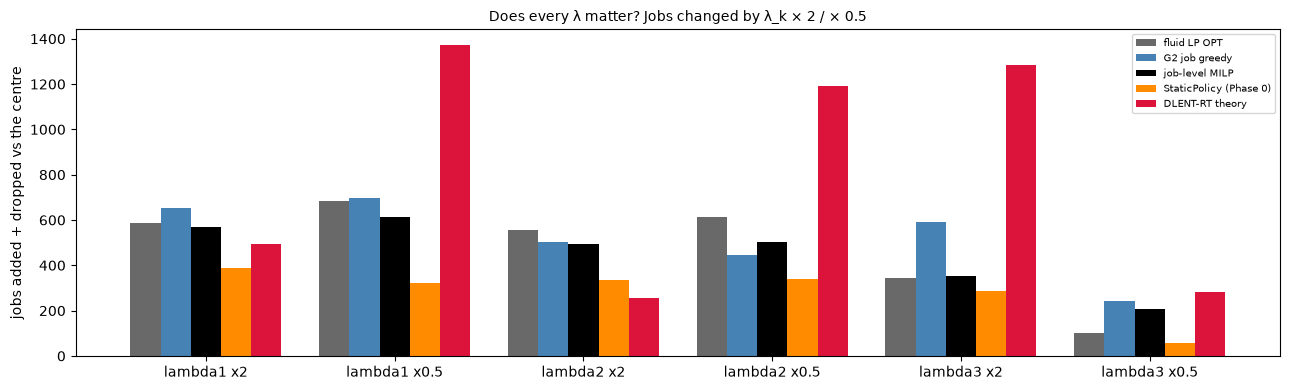

In [8]:
print(f"DLENT-RT perturbation runs: sum of run times {float(META['DLENT-RT perturbation runs, sum of run times s']):,.0f} s; "
      f"all StaticPolicy / DLENT-RT runs in parallel: wall {float(META['StaticPolicy/DLENT-RT runs (parallel) wall s']):,.0f} s")
PM = ["fluid LP OPT", "G2 job greedy", "job-level MILP", "StaticPolicy (Phase 0)", "DLENT-RT theory"]
show = ["perturbation", "n_admitted centre", "n_admitted", "jobs added", "jobs dropped", "jobs changed",
        "d sum_CV", "d sum_PR", "d sum_CO"]
for m in PM:
    print(f"\n=== {m}")
    display(PERT[PERT.model == m][show].set_index("perturbation").style.format(precision=1))
LEAST = (PERT.groupby(["model", "lambda_k"])["jobs changed"].sum().unstack("lambda_k").loc[PM])
LEAST["least-changing lambda"] = LEAST.idxmin(axis=1)
display(LEAST.style.format(precision=1, subset=["lambda1", "lambda2", "lambda3"]))

fig, ax = plt.subplots(figsize=(13, 4))
labs = PERT.perturbation.unique()
xw = np.arange(len(labs))
for i, m in enumerate(PM):
    g = PERT[PERT.model == m].set_index("perturbation").loc[labs]
    ax.bar(xw + (i - 2) * 0.16, g["jobs changed"], 0.16, color=STYLE[m][0], label=m)
ax.set_xticks(xw, labs); ax.set_ylabel("jobs added + dropped vs the centre")
ax.legend(fontsize=7); ax.set_title("Does every λ matter? Jobs changed by λ_k × 2 / × 0.5", fontsize=10)
plt.tight_layout(); savefig(fig, "lambda_perturbations"); plt.show()

## 8. Weighted sum vs Chebyshev (standard augmented form)

**Standard form** (`pareto.chebyshev_fluid`): max t + ρ·Σ_k g_k s.t. t ≤ g_k / w_k for every k with w_k > 0,
g_k = (f_k − nadir_k)/(ideal_k − nadir_k), f = (CV, PR, −CO): the point where the ray from the nadir in direction w meets
the front; a larger weight = a more important objective. ρ (above) makes the solution Pareto-optimal, not only weakly;
zero-weight objectives have no constraint but stay in the augmentation term. (It is not the same scalarization as
min max_k w_k·(ideal_k − f_k)/range_k, which follows the ray from the ideal in direction 1/w.)

**On the fluid LP**: the set of achievable objective vectors is convex (an LP), so every Pareto-optimal point is
supported by some weight vector. Below, for every grid weight: the Chebyshev point, its dominance slack (0 = Pareto
optimal) and its normalised distance to the nearest weighted-sum grid point. A non-zero distance means the
Chebyshev point is a Pareto point the 16 weighted-sum weights do not hit (it is still supported by SOME weight).

In [9]:
ws = RES[(RES.model == "fluid LP OPT") & RES.on_grid]
ch = RES[(RES.model == "Chebyshev fluid LP") & RES.on_grid]
FW = np.column_stack([ws.sum_CV, ws.sum_PR, -ws.sum_CO])
FC = np.column_stack([ch.sum_CV, ch.sum_PR, -ch.sum_CO])
scale = np.where(FW.max(axis=0) - FW.min(axis=0) > 0, FW.max(axis=0) - FW.min(axis=0), 1.0)
dist = np.sqrt((((FC[:, None, :] - FW[None, :, :]) / scale) ** 2).sum(axis=2)).min(axis=1)
CMP = pd.DataFrame({"lambda (w = lambda/3)": ch["lambda"].to_numpy(),
                    "Chebyshev CV": ch.sum_CV.to_numpy(), "Chebyshev PR": ch.sum_PR.to_numpy(),
                    "Chebyshev CO": ch.sum_CO.to_numpy(), "dominance slack": ch.dominance_slack.to_numpy(),
                    "distance to nearest weighted-sum point": dist,
                    "same as a weighted-sum point (< 1e-6)": dist < 1e-6}).set_index("lambda (w = lambda/3)")
display(CMP.style.format(precision=4))
print(f"Chebyshev points equal to a weighted-sum grid point: {int((dist < 1e-6).sum())} / {len(dist)}; "
      f"max dominance slack (Chebyshev) {ch.dominance_slack.max():.2e}, (weighted sum) {ws.dominance_slack.max():.2e}")

,Chebyshev CV,Chebyshev PR,Chebyshev CO,dominance slack,distance to nearest weighted-sum point,same as a weighted-sum point (< 1e-6)
lambda (w = lambda/3),,,,,,
"(0, 0, 3)",5.8759,1.4080,0.0005,0.0002,0.0001,False
"(0, 0.75, 2.25)",24080.7208,12985.0528,497.8621,0.0004,0.3739,False
"(0, 1.5, 1.5)",76877.0020,29467.9266,4698.3463,0.0001,0.1934,False
"(0, 2.25, 0.75)",103192.0328,37733.5119,12176.4552,0.0001,0.2013,False
"(0, 3, 0)",110482.0711,40079.6310,17359.3396,-0.0000,0.0000,False
"(0.75, 0, 2.25)",41351.0124,10957.7344,870.6801,0.0005,0.3969,False
"(0.75, 0.75, 1.5)",58954.5963,18112.7609,1706.4122,0.0000,0.1808,False
"(0.75, 1.5, 0.75)",98114.4743,35986.2269,9778.8347,0.0000,0.0543,False
"(0.75, 2.25, 0)",110482.0711,40079.6310,17359.3396,-0.0000,0.0000,False


Chebyshev points equal to a weighted-sum grid point: 0 / 16; max dominance slack (Chebyshev) 4.99e-04, (weighted sum) 7.05e-04


**On a discrete toy front** (not the real data): points A = (1, 0), B = (0, 1) and C = (0.4, 0.4), plus the dominated
D = (0.3, 0.3). C is Pareto-optimal but lies below the segment AB (unsupported): no weighted sum selects it, Chebyshev
does. On the real instance we make NO claim of non-convexity: the fluid front is convex by construction, and the job
MILP / G2 points are each the optimum of their own weighted sum, so they are supported by construction; finding
unsupported job-level points would need a Chebyshev MILP, which is not run here.

,weighted sum picks,Chebyshev picks
"A (1, 0)",51,1
"B (0, 1)",50,1
"C (0.4, 0.4)",0,99


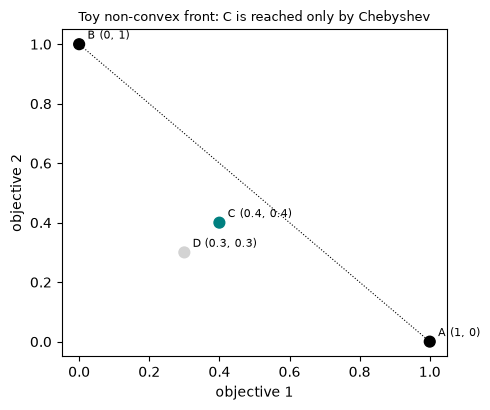

In [10]:
F = np.array([[1.0, 0.0, 0.0], [0.0, 1.0, 0.0], [0.4, 0.4, 0.0], [0.3, 0.3, 0.0]])
ideal_t, nadir_t = F.max(axis=0), F.min(axis=0)
alphas = np.linspace(0, 1, 101)
ws_pick = [int(np.argmax(F @ np.array([a, 1 - a, 0.0]))) for a in alphas]
ch_pick = [pareto.chebyshev_discrete(F, (a, 1 - a, 0.0), ideal_t, nadir_t) for a in alphas]
names = np.array(["A (1, 0)", "B (0, 1)", "C (0.4, 0.4)", "D (0.3, 0.3)"])
TOY = pd.DataFrame({"weighted sum picks": pd.Series(names[ws_pick]).value_counts(),
                    "Chebyshev picks": pd.Series(names[ch_pick]).value_counts()}).fillna(0).astype(int)
display(TOY)
fig, ax = plt.subplots(figsize=(5, 4.2))
ax.scatter(F[:, 0], F[:, 1], c=["k", "k", "teal", "lightgray"], s=60)
for (x, y), n in zip(F[:, :2], names):
    ax.annotate(n, (x, y), textcoords="offset points", xytext=(6, 4), fontsize=8)
ax.plot([1, 0], [0, 1], "k:", lw=0.8)
ax.set_xlabel("objective 1"); ax.set_ylabel("objective 2")
ax.set_title("Toy non-convex front: C is reached only by Chebyshev", fontsize=9)
plt.tight_layout(); savefig(fig, "toy_front_chebyshev"); plt.show()

## 9. The weight simplex: Σ CV, Σ PR, Σ CO of the job-level MILP and of the fluid LP per λ

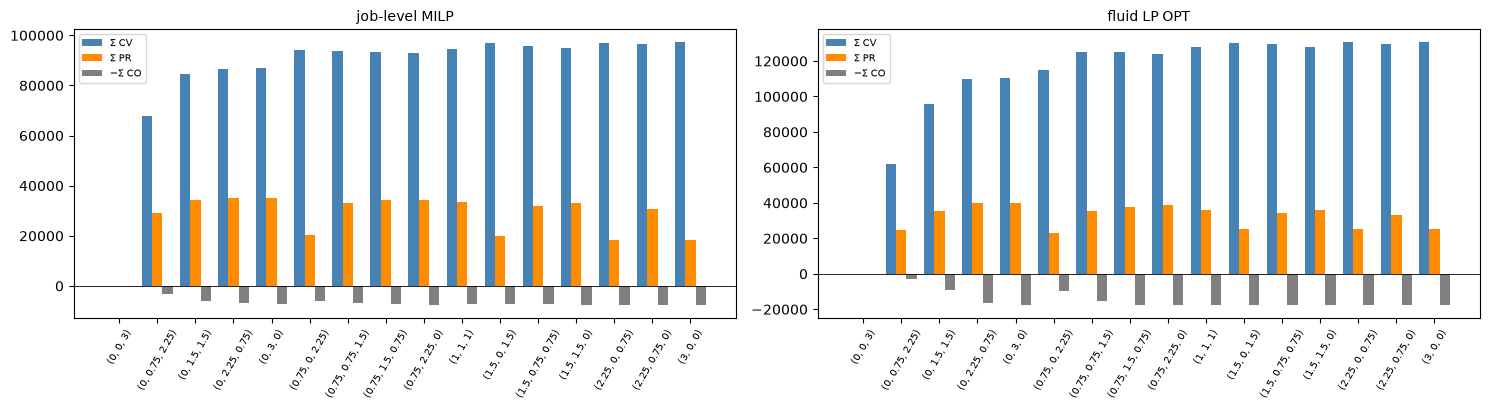

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), sharey=False)
for ax, m in zip(axes, ["job-level MILP", "fluid LP OPT"]):
    g = RES[(RES.model == m) & RES.on_grid].sort_values(["l1", "l2"])
    x = np.arange(len(g))
    ax.bar(x - 0.27, g.sum_CV, 0.27, color="steelblue", label="Σ CV")
    ax.bar(x, g.sum_PR, 0.27, color="darkorange", label="Σ PR")
    ax.bar(x + 0.27, -g.sum_CO, 0.27, color="gray", label="−Σ CO")
    ax.set_xticks(x, g["lambda"], rotation=60, fontsize=7); ax.axhline(0, color="k", lw=0.6)
    ax.set_title(m, fontsize=10); ax.legend(fontsize=7)
plt.tight_layout(); savefig(fig, "objectives_per_lambda"); plt.show()

## 10. Hypervolume

Exact 3-D hypervolume (`pareto.hypervolume_3d`) of each model's points, objectives (CV, PR, −CO) maximised, with a
COMMON reference point for every model: the componentwise worst value over all grid / subset rows of all models,
pushed out by 1% of the range (so boundary points still count). "7-point subset" makes the models comparable on the
same λ.

In [12]:
print("reference point (CV, PR, -CO) $:", META["hypervolume reference point (CV, PR, -CO) $"])
hvp = HV.pivot(index="model", columns="points", values="hypervolume")
display(hvp.loc[[m for m in [*MODELS, "Chebyshev fluid LP (legacy, inverted)"] if m in hvp.index]]
        .style.format("{:.4e}"))

reference point (CV, PR, -CO) $: [-1304.5380121744142, -400.79631830616836, -17922.81388072532]


points,7-point subset,all its grid points
model,,
job-level MILP,4.1032e+13,4.7441e+13
fluid LP OPT,3.2048e+13,4.7052e+13
Chebyshev fluid LP,3.8125e+13,5.3322e+13
G2 job greedy,3.4852e+13,4.1529e+13
StaticPolicy (Phase 0),5.7833e+12,5.7833e+12
DLENT-RT theory,4.6539e+12,4.6539e+12
"Chebyshev fluid LP (legacy, inverted)",3.8093e+13,5.1396e+13


## 11. Legacy Chebyshev (inverted weight orientation), kept for reference

The previous form max t s.t. t ≤ w_k·(f_k − nadir_k)/(ideal_k − nadir_k) (`pareto.chebyshev_fluid_legacy`) was
WRONG for a weight study: a LARGER w_k makes objective k's constraint LOOSER, so objective k matters LESS (inverted
orientation), and without augmentation the LP is degenerate (t is set by the smallest positive weight; many x tie).
Standard vs legacy at the same weights:

In [13]:
lg = RES[(RES.model == "Chebyshev fluid LP (legacy, inverted)") & RES.on_grid].set_index("lambda")
st_ = RES[(RES.model == "Chebyshev fluid LP") & RES.on_grid].set_index("lambda")
display(st_[["sum_CV", "sum_PR", "sum_CO", "chebyshev_t"]].join(
    lg[["sum_CV", "sum_PR", "sum_CO", "chebyshev_t"]], lsuffix=" (standard)", rsuffix=" (legacy)")
    .style.format(precision=2))

,sum_CV (standard),sum_PR (standard),sum_CO (standard),chebyshev_t (standard),sum_CV (legacy),sum_PR (legacy),sum_CO (legacy),chebyshev_t (legacy)
lambda,,,,,,,,
"(0, 0, 3)",5.88,1.41,0.00,1.00,0.00,0.00,0.00,1.00
"(0, 0.75, 2.25)",24080.72,12985.05,497.86,1.30,103192.03,37733.51,12176.46,0.24
"(0, 1.5, 1.5)",76877.00,29467.93,4698.35,1.47,76764.08,29467.93,4698.34,0.37
"(0, 2.25, 0.75)",103192.03,37733.51,12176.46,1.26,23955.71,12985.06,497.85,0.24
"(0, 3, 0)",110482.07,40079.63,17359.34,1.00,110476.86,40079.63,17359.18,1.00
"(0.75, 0, 2.25)",41351.01,10957.73,870.68,1.27,121083.84,24023.71,12255.06,0.23
"(0.75, 0.75, 1.5)",58954.60,18112.76,1706.41,1.81,111628.63,34295.93,10153.03,0.21
"(0.75, 1.5, 0.75)",98114.47,35986.23,9778.83,1.80,93916.45,19403.00,4970.09,0.18
"(0.75, 2.25, 0)",110482.07,40079.63,17359.34,1.33,130453.80,25400.20,17745.31,0.25


## 12. Runtime

In [14]:
display(ALL.groupby("model")["runtime_s"].agg(["count", "sum", "max"]).style.format(precision=2))
print(f"total script runtime: {float(META['total runtime s']):,.0f} s")

,count,sum,max
model,,,
Chebyshev fluid LP,16,0.49,0.05
"Chebyshev fluid LP (legacy, inverted)",16,0.52,0.06
DLENT-RT theory,13,3715.20,449.30
G2 job greedy,22,4.16,0.24
StaticPolicy (Phase 0),13,2.59,0.28
fluid LP OPT,22,0.52,0.04
job-level MILP,22,391.83,84.23


total script runtime: 1,025 s


## 13. All tables as markdown (`nb04_tables.md` in the results folder)

In [15]:
def _fmt(v):
    if isinstance(v, (bool, np.bool_)):
        return str(v)
    if isinstance(v, (int, np.integer)):
        return f"{v:,}"
    if isinstance(v, (float, np.floating)):
        return "nan" if not np.isfinite(v) else (f"{v:,.2f}" if abs(v) >= 1 or v == 0 else f"{v:.3g}")
    return str(v)


def md_table(df, index_name):
    head = "| " + index_name + " | " + " | ".join(map(str, df.columns)) + " |"
    sep = "|" + "---|" * (len(df.columns) + 1)
    body = ["| " + " / ".join(map(str, k if isinstance(k, tuple) else (k,))) + " | "
            + " | ".join(_fmt(v) for v in row) + " |" for k, row in zip(df.index, df.itertuples(index=False))]
    return "\n".join([head, sep, *body])


main_cols = ["sum_CV", "sum_PR", "sum_CO", "scalarised", "n_admitted", "nondominated"]
md = [f"# nb04 tables{' — regime ' + REGIME if REGIME else ''} (generated by the notebook; do not edit by hand)\n",
      f"Results cached at commit `{META['commit']}`, configs/default.yaml blob `{META['configs/default.yaml blob']}`"
      + (f", regime blob `{META['regime blob']}`" if REGIME else "") + f"; s_C = {float(META['s_C']):.4f}.\n"]
for m in MODELS:
    g = RES[RES.model == m].set_index("lambda")[main_cols]
    md += [f"## {m}\n", md_table(g, "lambda"), ""]
md += ["## Corners\n", md_table(corner[["model", "lambda", "n_admitted", "sum_CV", "sum_PR", "sum_CO", "corner_solution"]]
                                  .set_index(["lambda", "model"]).sort_index(), "lambda / model"), "",
       "## DLENT-RT and StaticPolicy vs the offline frontier\n", md_table(VSF, "model / lambda"), "",
       "## Does every lambda matter? (jobs changed vs the centre, x2 + x0.5)\n", md_table(LEAST, "model"), "",
       "## Weighted sum vs Chebyshev (fluid LP)\n", md_table(CMP, "lambda"), "",
       "## Hypervolume\n", md_table(hvp, "model"), ""]
(PDIR / "nb04_tables.md").write_text("\n".join(md))
print("markdown ->", PDIR / "nb04_tables.md")

markdown -> /Users/francescodangolo/Projects/dlent_rt/reports/week30/pareto_small_cluster/nb04_tables.md
